# Ensembles and prediction intervals

In this notebook we look at how much model coefficients and predictions vary when the dataset or the model changes, how ensembles of models average out this variation, and how to obtain prediction intervals for any model with the bootstrap.

# Notebook setup

Run the next cell first. In Google Colab it clones the course repository, then imports the libraries and the course modules. If you cloned the repository and run the notebook locally (see the README), it only does the imports.

In [1]:
#@title Setup: clone the course repository (Google Colab only) and import libraries
import os
import sys

# In Google Colab the repository is cloned and the notebook moves into its "scripts" folder.
if "google.colab" in sys.modules and not os.path.isdir("modules"):
    if not os.path.isdir("analytics-course-scripts"):
        !git clone -q https://github.com/DataHow/analytics-course-scripts.git
    os.chdir("analytics-course-scripts/scripts")
# When the notebook is started from the repository root, move into "scripts"
if os.path.isdir("scripts/modules"):
    os.chdir("scripts")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import copy
import warnings
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.metrics import root_mean_squared_error
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.svm import SVR
warnings.filterwarnings("ignore")

pd.set_option("display.max_rows", 30)

# course modules (folder scripts/modules)
from modules import simulator, plothelpers


# Import or generate the in silico dataset

At the beginning of each notebook you decide whether to import the pre-generated experiments or to generate your own dataset with the in silico process model. For details on the process simulator, see the notebook `00_Process_Introduction.ipynb`.

* To import the dataset set `DATASET_SOURCE = "import"`.
* To generate a new dataset set `DATASET_SOURCE = "generate"`. The files are written to the folder `generated/`.

When running the notebook for the first time, we recommend the "import" option.


In [2]:
""" Select dataset source, one of (import, generate) """
DATASET_SOURCE = "import"

In [3]:
if DATASET_SOURCE == "import":
    # Define filename to import
    FILENAME = "owu.csv"
    FILEPATH = "datasets/"
    # Import OWU data
    doe = pd.read_csv(FILEPATH+FILENAME.replace(".csv","_doe.csv"),index_col=None, usecols =["feed_start","feed_end","Glc_feed_rate","Glc_0","VCD_0"])
    owu = pd.read_csv(FILEPATH+FILENAME,index_col=None, usecols = ["X:VCD", "X:Glc", "X:Lac", "X:Titer","W:Feed"])
    owu.index = pd.MultiIndex.from_product([list(range(int(len(owu)/15))),list(range(15))], names=["run","time"])
    # Import OWU Test data
    FILENAME = "owu_test.csv"
    doe_test = pd.read_csv(FILEPATH+FILENAME.replace(".csv","_doe.csv"),index_col=None, usecols =["feed_start","feed_end","Glc_feed_rate","Glc_0","VCD_0"])
    owu_test = pd.read_csv(FILEPATH+FILENAME,index_col=None, usecols = ["X:VCD", "X:Glc", "X:Lac", "X:Titer","W:Feed"])
    owu_test.index = pd.MultiIndex.from_product([list(range(int(len(owu_test)/15))),list(range(15))], names=["run","time"])

In [4]:
if DATASET_SOURCE == "generate":
    # DOE Dataset definition (variable = [lower bound, upper bound])
    # Model parameters: Dictate the behaviour of the cell process
    MU_G_MAX = 0.05
    MU_D_MAX = 0.025
    K_G_GLC  = 1
    K_I_LAC  = 30
    K_D_LAC  = 50
    K_GLC    = 0.04
    K_LAC    = 0.06
    K_PROD   = 1
    # Process parameters: Conditions at which process is run
    FEED_START = [1, 4]
    FEED_END = [8, 12]
    GLC_FEED_RATE = [5, 20]
    GLC_0 = [10, 80.0]
    VCD_0 = [0.1, 1.0]
    # Number of experiments to generate
    NUM_RUNS = 40
    # Filename and filepath for the dataset
    FILENAME = "owu.csv"
    FILEPATH = "generated/"
    # Collect parameters to dictionary
    VAR_LIMS = {"mu_g_max":MU_G_MAX, "mu_d_max": MU_D_MAX, "K_g_Glc" : K_G_GLC, "K_I_Lac" : K_I_LAC, "K_d_Lac" : K_D_LAC, "k_Glc" : K_GLC, "k_Lac" : K_LAC, "k_Prod" : K_PROD,
        "feed_start" : FEED_START,"feed_end" : FEED_END, "Glc_feed_rate" : GLC_FEED_RATE, "Glc_0" : GLC_0, "VCD_0" : VCD_0}
    # Generate Dataset
    data = simulator.generate_data(VAR_LIMS, NUM_RUNS, FILEPATH + FILENAME)
    # Import DOE
    doe = pd.read_csv(FILEPATH+FILENAME.replace(".csv","_doe.csv"),index_col=None, usecols =["feed_start","feed_end","Glc_feed_rate","Glc_0","VCD_0"])
    # Import OWU
    owu = pd.read_csv(FILEPATH+FILENAME,index_col=None, usecols = ["X:VCD", "X:Glc", "X:Lac", "X:Titer","W:Feed"])
    owu.index = pd.MultiIndex.from_product([list(range(NUM_RUNS)),list(range(15))], names=["run","time"])

Generate the regression targets for our data (titer and aggregates). In this notebook we predict the **aggregates** at the end of the process from the initial conditions (DOE), a harder target than the titer.

In [5]:
# Size of test set (up to 50)
NUM_TEST = 50
owu_test = owu_test.loc[0:NUM_TEST-1, slice(None)]
doe_test = doe_test.loc[0:NUM_TEST-1]
# Rename columns
doe.columns = ["F:start","F:end","F:rate","GLC:0","VCD:0"]
doe_test.columns = ["F:start","F:end","F:rate","GLC:0","VCD:0"]
# Train set
bwu = simulator.generate_bwu(owu)
y1 = simulator.generate_y(bwu,return_aggr=False)
y2 = simulator.generate_y(bwu,return_aggr=True)
# Test set
bwu_test = simulator.generate_bwu(owu_test)
y1_test = simulator.generate_y(bwu_test,return_aggr=False)
y2_test = simulator.generate_y(bwu_test,return_aggr=True)

# Varying the dataset

We first look at how the model and its predictions would change if the dataset were slightly different.

The coefficients below come from a regularized linear model (Lasso with cross-validated penalty) on polynomial features of the initial conditions. One usually decides whether a variable is important for the process based on the size of its coefficient compared to the others, or based on p-values.


In [6]:
""" Normalize data """
USE_NORMALIZATION = True
""" Polynomial degree of features """
USE_POLYDEGREE = 2
""" Add only interaction between features"""
USE_INTERACTIONSONLY = False

In [7]:
# Define pipeline
poly_features = PolynomialFeatures(degree=USE_POLYDEGREE, interaction_only=USE_INTERACTIONSONLY,include_bias=False)
standard_scaler = StandardScaler(with_mean=USE_NORMALIZATION, with_std=USE_NORMALIZATION)
reg_model = LassoCV()
pipe = Pipeline([('features', poly_features),
                 ('scaler', standard_scaler),
                 ('model', reg_model)])
# Fit model
X = doe
y = y2
pipe.fit(X,y)
# Feature Names & Coefficients
X_columns = poly_features.get_feature_names_out()
X_preproc = pipe[:-1].transform(X)
coefs = reg_model.coef_


In [8]:
#@title Plot the model coefficients
# Plot coefs
fig = px.bar(x=list(X_columns), y=coefs.reshape(-1), title="Model coefficients",labels={'x':"Variables", 'y':"Estimated Coefficients"})
fig.update_layout(xaxis_tickangle=90)
fig.show()


## Cross-validation subsets

There are several ways to obtain slightly different datasets of the same process. We could simulate the same conditions again and, due to noise, the dataset would be different. A simpler way is to work with the existing dataset and take different subsets of it.

We do this by running a 5-fold cross-validation on our dataset of 50 experiments and repeating it 5 times. The 5-fold CV means we train the model with 40 experiments and keep 10 experiments as holdout. This is repeated 5 x 5 = 25 times.

Therefore we obtain 25 models trained on different subsets of 40 experiments:


In [9]:
# Variation of the coefficients across the repeated cross-validation
CV = RepeatedKFold(n_splits=5, n_repeats=5, random_state=0)
variation_pipe = cross_validate(pipe,X,y,cv=CV,return_estimator=True)
variation_coef = pd.DataFrame([est[-1].coef_.reshape(-1) for est, (train_idx, _) in zip(variation_pipe["estimator"], CV.split(X,y))],columns=X_columns)
fig = px.box(variation_coef,points='all')
fig.update_layout(xaxis_tickangle=90,title="Variation in Coefficients",yaxis_title='Coefficient Value',xaxis_title='Variables')
fig.show()


We can see that the model coefficients vary quite significantly. The box plots and the individual points next to them visualize the distribution of the parameters given the model and the data. Next we look at how this translates into the predictions on the test set:

In [10]:
#@title Predict on the test set with the 25 models and plot the variation
# Predict on the test set with each of the 25 models
X_test = doe_test
y_test = y2_test
variation_pred = pd.DataFrame([est.predict(X_test) for est, (train_idx, _) in zip(variation_pipe["estimator"], CV.split(X,y))])
fig = go.Figure()
for i in range(len(y_test)):
    fig.add_trace(go.Box(y=variation_pred.iloc[:,i],name=i,boxpoints='all',marker_color = px.colors.qualitative.Plotly[0]))
    fig.add_trace(go.Box(y=y_test.values[i], name=i,marker=dict(color=px.colors.qualitative.Plotly[1])))
fig.update_layout(title="Variation in Predictions (blue: prediction, red: observation)",showlegend=False,xaxis_title="Test Set Observation Number",yaxis_title="Predicted Value",)
fig.show()

# Varying the models

Another option to obtain an ensemble is to vary the models, i.e. the underlying assumptions about the data.


## Averaging predictions

Here we simply average the predictions of 4 different models: Lasso, Ridge, random forest and support vector regression (SVR).


In [11]:
# Define different models
reg1 = Pipeline([('features', PolynomialFeatures(degree=USE_POLYDEGREE, interaction_only=USE_INTERACTIONSONLY,include_bias=False)),
                 ('scaler', StandardScaler(with_mean=USE_NORMALIZATION, with_std=USE_NORMALIZATION)),
                 ('model', LassoCV())])
reg2 = Pipeline([('features', PolynomialFeatures(degree=USE_POLYDEGREE, interaction_only=USE_INTERACTIONSONLY,include_bias=False)),
                 ('scaler', StandardScaler(with_mean=USE_NORMALIZATION, with_std=USE_NORMALIZATION)),
                 ('model', RidgeCV())])
reg3 = Pipeline([('features', PolynomialFeatures(degree=USE_POLYDEGREE, interaction_only=USE_INTERACTIONSONLY,include_bias=False)),
                 ('scaler', StandardScaler(with_mean=USE_NORMALIZATION, with_std=USE_NORMALIZATION)),
                 ('model', RandomForestRegressor())])
reg4 = Pipeline([('features', PolynomialFeatures(degree=USE_POLYDEGREE, interaction_only=USE_INTERACTIONSONLY,include_bias=False)),
                 ('scaler', StandardScaler(with_mean=USE_NORMALIZATION, with_std=USE_NORMALIZATION)),
                 ('model', SVR())])
# Train models
models = [reg1,reg2,reg3,reg4]
for reg in models:
    reg.fit(X,y)
# Average predictions
reg_avg = VotingRegressor([("Lasso", reg1), ("Ridge", reg2), ("RF", reg3), ("SVR", reg4)])
reg_avg.fit(X,y)
# Obtain predictions
preds = [reg_avg.predict(X_test).reshape(-1)]
for reg in models:
    preds.append(reg.predict(X_test).reshape(-1))
# Obtain RMSE
rmses = []
for i in range(len(preds)):
    rmses.append(round(root_mean_squared_error(y_test, preds[i]) / np.std(np.array(y_test)),3))


In [12]:
#@title Plot the predictions of the models and of their average
xgrid=list(range(NUM_TEST))
fig = go.Figure()
fig.add_trace(go.Scatter(x=xgrid,y=y_test.values.flatten(),name='Observations',mode='markers',marker=dict(symbol='square',size=10,color=px.colors.qualitative.Plotly[1])))
fig.add_trace(go.Scatter(x=xgrid,y=preds[0],name=f'Average (rmse {rmses[0]})',mode='markers',marker=dict(symbol='star',size=10,color=px.colors.qualitative.Plotly[0])))
fig.add_trace(go.Scatter(x=xgrid,y=preds[1],name=f'Lasso (rmse {rmses[1]})',mode='markers',marker=dict(size=8,color=px.colors.qualitative.Plotly[2])))
fig.add_trace(go.Scatter(x=xgrid,y=preds[2],name=f'Ridge (rmse {rmses[2]})',mode='markers',marker=dict(size=8,color=px.colors.qualitative.Plotly[7])))
fig.add_trace(go.Scatter(x=xgrid,y=preds[3],name=f'RF (rmse {rmses[3]})',mode='markers',marker=dict(size=8,color=px.colors.qualitative.Plotly[4])))
fig.add_trace(go.Scatter(x=xgrid,y=preds[4],name=f'SVR (rmse {rmses[4]})',mode='markers',marker=dict(size=8,color=px.colors.qualitative.Plotly[9])))
fig.update_layout(xaxis = dict(tickmode = 'array',tickvals = xgrid),xaxis_title="Test Set Observation Number",yaxis_title="Predicted Value",title='Variation in Prediction across Models')
fig.show()

## Stacking models

It is sometimes tedious to find the model which performs best on a given dataset. Stacking provides an alternative by combining the outputs of several learners, without the need to choose one model specifically. The performance of stacking is usually close to the best model and sometimes it outperforms every individual model.

Here we combine the 4 learners (linear and non-linear) and use a Lasso regressor to combine their outputs.


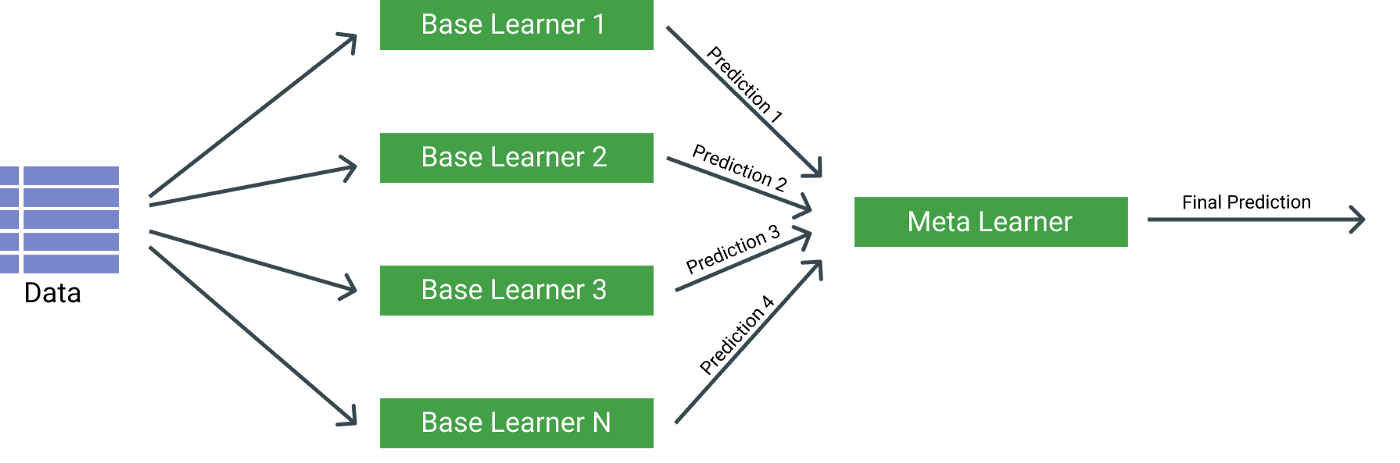

In [13]:
# Stacked model: the final estimator learns how to weight the 4 base models
reg_stack = StackingRegressor(estimators=[("Lasso", reg1), ("Ridge", reg2), ("RF", reg3), ("SVR", reg4)], final_estimator=LassoCV())
reg_stack.fit(X,y)
# Obtain predictions & metric
preds.append(reg_stack.predict(X_test).reshape(-1))
rmses.append(round(root_mean_squared_error(y_test, preds[-1]) / np.std(np.array(y_test)),3))


In [14]:
#@title Plot the predictions of the models and of the stacked model
# Plot predictions
fig = go.Figure()
fig.add_trace(go.Scatter(x=xgrid,y=y_test.values.flatten(),name='Observations',mode='markers',marker=dict(symbol='square',size=10,color=px.colors.qualitative.Plotly[1])))
fig.add_trace(go.Scatter(x=xgrid,y=preds[-1],name=f'Stacking (rmse {rmses[-1]})',mode='markers',marker=dict(symbol='star',size=10,color=px.colors.qualitative.Plotly[0])))
fig.add_trace(go.Scatter(x=xgrid,y=preds[1],name=f'Lasso (rmse {rmses[1]})',mode='markers',marker=dict(size=8,color=px.colors.qualitative.Plotly[2])))
fig.add_trace(go.Scatter(x=xgrid,y=preds[2],name=f'Ridge (rmse {rmses[2]})',mode='markers',marker=dict(size=8,color=px.colors.qualitative.Plotly[7])))
fig.add_trace(go.Scatter(x=xgrid,y=preds[3],name=f'RF (rmse {rmses[3]})',mode='markers',marker=dict(size=8,color=px.colors.qualitative.Plotly[4])))
fig.add_trace(go.Scatter(x=xgrid,y=preds[4],name=f'SVR (rmse {rmses[4]})',mode='markers',marker=dict(size=8,color=px.colors.qualitative.Plotly[9])))
fig.update_layout(xaxis = dict(tickmode = 'array',tickvals = xgrid),xaxis_title="Test Set Observation Number",yaxis_title="Predicted Value",title='Variation in Prediction across Models')
fig.show()


# Prediction intervals

A prediction interval is calculated from some combination of the estimated **variance of the model** and the **variance of the outcome variable**.

Prediction intervals are easy to describe but difficult to calculate in practice. In simple cases like linear regression we can estimate the prediction interval directly.

For nonlinear regression algorithms, such as artificial neural networks or random forests, it is a lot more challenging and requires specialized techniques. General techniques such as bootstrap resampling can be used, but they are computationally expensive.

The following list summarizes some popular methods to estimate the prediction uncertainty of linear or nonlinear machine learning models:

* The parametric method, using estimated statistics from mean-variance estimation.
* The bootstrap method, using data resampling to build an ensemble of models.
* The Bayesian method, from Bayesian modelling and statistics.
* Quantile regression, by directly learning the quantiles.
* Others like the delta method, conformal prediction, etc.

We make the calculation of a prediction interval concrete with a worked example in the next section. We compare only the parametric method with the bootstrap method.


## Bootstrap prediction interval


A reliable way to calculate prediction intervals for machine learning algorithms is the bootstrap. This is a general technique for estimating statistics that can be used to calculate empirical prediction intervals, regardless of the distribution of the predicted data (e.g. non-Gaussian).

The algorithm below was introduced in [Kumar and Srivastava (2012)](https://ntrs.nasa.gov/citations/20130014367). It combines the variation of the predictions of models trained on bootstrap samples (model uncertainty) with the distribution of the validation residuals (noise).


### Linear model example

The parametric interval (red) assumes normally distributed residuals; the bootstrap interval (grey) makes no such assumption. For a linear model with Gaussian noise both intervals agree.


In [15]:
def prediction_interval(model, X_train, y_train, x0, alpha: float = 0.05):
  ''' Compute a prediction interval around the model's prediction of x0.

  INPUT
    model
      A predictive model with `fit` and `predict` methods
    X_train: numpy array of shape (n_samples, n_features)
      A numpy array containing the training input data
    y_train: numpy array of shape (n_samples,)
      A numpy array containing the training target data
    x0
      A new data point, of shape (n_features,)
    alpha: float = 0.05
      The prediction uncertainty

  OUTPUT
    A triple (`lower`, `pred`, `upper`) with `pred` being the prediction
    of the model and `lower` and `upper` constituting the lower- and upper
    bounds for the prediction interval around `pred`, respectively. '''

  # Number of training samples
  n = X_train.shape[0]

  # The authors choose the number of bootstrap samples as the square root
  # of the number of samples
  nbootstraps = np.sqrt(n).astype(int)

  # Compute the m_i's and the validation residuals
  bootstrap_preds, val_residuals = np.empty(nbootstraps), []
  for b in range(nbootstraps):
    train_idxs = np.random.choice(range(n), size = n, replace = True)
    val_idxs = np.array([idx for idx in range(n) if idx not in train_idxs])
    model.fit(X_train[train_idxs, :], y_train[train_idxs])
    preds = model.predict(X_train[val_idxs])
    val_residuals.append(y_train[val_idxs] - preds)
    bootstrap_preds[b] = model.predict(x0).item()
  bootstrap_preds -= np.mean(bootstrap_preds)
  val_residuals = np.concatenate(val_residuals)

  # Compute the prediction and the training residuals
  model.fit(X_train, y_train)
  preds = model.predict(X_train)
  train_residuals = y_train - preds

  # Take percentiles of the training- and validation residuals to enable
  # comparisons between them
  val_residuals = np.percentile(val_residuals, q = np.arange(100))
  train_residuals = np.percentile(train_residuals, q = np.arange(100))

  # Compute the .632+ bootstrap estimate for the sample noise and bias
  no_information_error = np.mean(np.abs(np.random.permutation(y_train) - \
    np.random.permutation(preds)))
  generalisation = np.abs(val_residuals.mean() - train_residuals.mean())
  no_information_val = np.abs(no_information_error - train_residuals)
  relative_overfitting_rate = np.mean(generalisation / no_information_val)
  weight = .632 / (1 - .368 * relative_overfitting_rate)
  residuals = (1 - weight) * train_residuals + weight * val_residuals

  # Construct the C set and get the percentiles
  C = np.array([m + o for m in bootstrap_preds for o in residuals])
  qs = [100 * alpha / 2, 100 * (1 - alpha / 2)]
  percentiles = np.percentile(C, q = qs)

  return percentiles[0], model.predict(x0), percentiles[1]

In [16]:
def lin_fun(X, noise_level):
  return 3*X-5+noise_level*np.random.randn(len(X))

X_train = np.linspace(0,100,100)
y_train = lin_fun(X_train, 20)

X_test = np.linspace(0,100,100)
y_test = lin_fun(X_test, 20)

lin_model = LinearRegression().fit(X_train.reshape(-1, 1),y_train)
y_pred = lin_model.predict(X_test.reshape(-1, 1))

lower, median, upper = prediction_interval(LinearRegression(), X_train.reshape(-1,1), y_train, X_test[0].reshape(1, -1))
plothelpers.plot_ensemble(X_train, y_train, X_test, y_test, y_pred, lin_model, upper, lower)

### Linear model with non-Gaussian errors

With a skewed (exponential) error distribution, the assumption of the parametric method, normally distributed errors, no longer holds, which is clearly visible in the plot below. The bootstrap prediction interval still covers the points well.


In [17]:
def non_lin_error(X):
  return 3*X-5+60*np.random.exponential(0.5,len(X))

In [18]:
X_train = np.linspace(0,100,100)
y_train = non_lin_error(X_train)

X_test = np.linspace(0,100,100)
y_test = non_lin_error(X_test)

lin_model = LinearRegression().fit(X_train.reshape(-1, 1),y_train)
y_pred = lin_model.predict(X_test.reshape(-1, 1))

lower, median, upper = prediction_interval(LinearRegression(),X_train.reshape(-1,1), y_train, X_test[0].reshape(1, -1))
plothelpers.plot_ensemble(X_train, y_train, X_test,y_test, y_pred, lin_model, upper, lower)

### Extreme overfitting with a decision tree

The higher the confidence of the model on the training data, the narrower the parametric prediction interval. In the extreme case of a single, fully grown decision tree, the parametric interval collapses to a single line, while the bootstrap prediction interval still provides a useful interval.


In [19]:
model = DecisionTreeRegressor()
model.fit(X_train.reshape(-1,1), y_train)
y_pred = model.predict(X_test.reshape(-1, 1))

lower, median, upper = prediction_interval(model,X_train.reshape(-1,1), y_train, X_test[0].reshape(1, -1))
plothelpers.plot_ensemble(X_train, y_train, X_test, y_test, y_pred, model, upper, lower)

# Tasks

1. Change the target from the aggregates (`y2`) to the titer (`y1`). Which model wins now and how large is the variation across the cross-validation subsets?
2. Set `USE_POLYDEGREE = 1`. How does the variation of the coefficients change, and how does the test error of the individual models and of the average change?
3. Replace the decision tree in the last example with a `RandomForestRegressor`. Does the parametric prediction interval become useful again?


In [20]:
# Your code here
